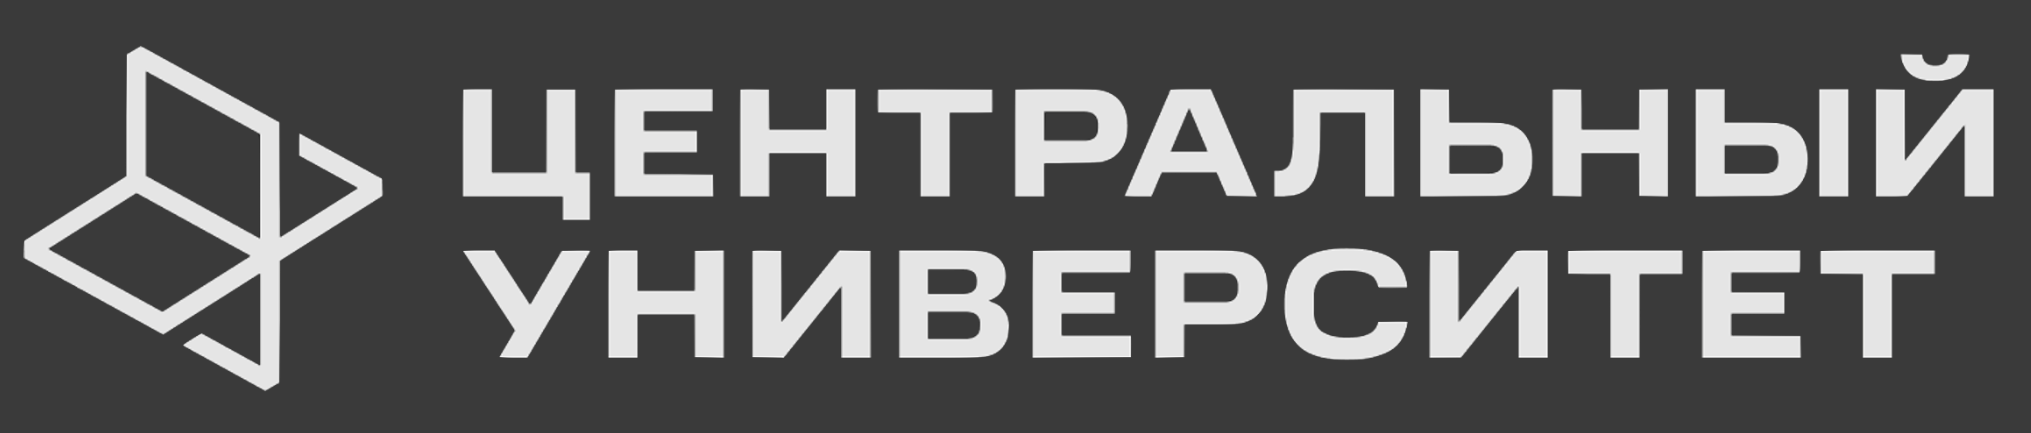

# Курс по Глубокому обучению

## Домашнее задание 3. Сверточные нейронные сети и аугментации (10 баллов)


# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если не сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл


**ФИО:**

**Группа:**


## О задании

В этом задании вы поработаете с датасетом фотографий разных видов спорта, решите задачу многоклассовой классификации, примените аугментации изображений и самостоятельно реализуете архитектуру ResNet18.

Каждая задача имеет «стоимость» в баллах (указана в скобках). Рекомендуем решать задания по порядку.

**Распределение баллов (10):** задание 1 — 1, задание 2 — 3, задание 3 — 4, задание 4 — 2. Бонусное задание необязательно.


<font color='OrangeRed'>**Обратите внимание!**</font> В данном задании вам, вероятно, понадобится возможность работы с GPU. Мы предлагаем выполнять задание в Google Colab. При желании и наличии GPU на домашнем компьютере можно работать локально.

Если работаете в Colab, выберите GPU: **Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU** (или другой доступный GPU).

<font color='OrangeRed'>**Важно!**</font> Сначала убедитесь, что код обучения отрабатывает хотя бы несколько итераций на CPU, и только затем переходите на GPU.


--------


# Задание


Хорошим тоном при написании моделей является фиксировать seed (некоторый параметр, от которого зависит результат работы рандомизированных алгоритмов), чтобы результаты обучения были воспроизводимы. Давайте и мы зафиксируем seed


In [49]:
import PIL
import torchvision
from PIL import Image
#!pip install --upgrade torchvision
from torchvision.transforms import v2
import pandas as pd
import numpy as np
import random
import torch
import os
from tqdm.auto import tqdm

def set_seed(seed: int = 42) -> None:
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)
    print(f"Random seed set as {seed}")

set_seed()


Random seed set as 42


В этот раз будем работать с датасетом фотографий разных видов спорта. Он уже за вас разделен train/val/test. Давайте скачаем его


In [50]:
%pip install -q gdown
from pathlib import Path
import zipfile
import gdown

if not Path('sports.csv').exists():
    if not Path('sports.zip').exists():
        gdown.download(id='1NIXpm_MSoAVBW5T2QOn6G_8_MHxwIBId', output='sports.zip', quiet=False)
    with zipfile.ZipFile('sports.zip') as archive:
        archive.extractall('.')


    scikit-learn (>=1.0.*) ; extra == 'pipelines'
                  ~~~~~~^
Note: you may need to restart the kernel to use updated packages.


## <font color='DarkOrange'> **Задание 1 [1 балл]** </font>


Описание фотографий лежит в файле `sports.csv`. Давайте откроем файл в виде pandas датафрейма и посмотрим на примеры фото


In [51]:
df = pd.read_csv("sports.csv")
df.head(10)


,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train
5,0,train/air hockey/006.jpg,air hockey,train
6,0,train/air hockey/007.jpg,air hockey,train
7,0,train/air hockey/008.jpg,air hockey,train
8,0,train/air hockey/009.jpg,air hockey,train
9,0,train/air hockey/010.jpg,air hockey,train


In [52]:
assert isinstance(df, pd.DataFrame)
assert 'filepaths' in df.columns
assert 'class id' in df.columns
assert 'data set' in df.columns
print('Отлично!')


Отлично!


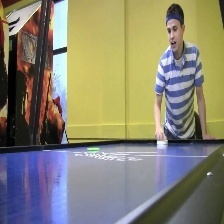

In [53]:
img_example = Image.open(df['filepaths'][0])
img_example


Давайте посмотрим, сколько различных видов спорта есть в датасете, чтобы понять, на сколько классов будем обучать модель


In [54]:
# Подсказка: посчитайте число уникальных значений в столбце с id класса и сохраните в n_classes
n_classes = len(df['class id'].unique())

In [55]:
assert isinstance(n_classes, (int, np.integer))
assert n_classes == 100, f'Ожидалось 100 классов, получено {n_classes}'
print('Отлично!')


Отлично!


Теперь выделим train/test части и сохраним картинки и таргет в виде списка, который будем потом запихивать в даталоадер.


In [56]:
train_df = df[df['data set'] == "train"]  # YOUR CODE HERE
test_df = df[df['data set'] == "test"]  # YOUR CODE HERE

In [57]:
assert len(train_df) > 0 and len(test_df) > 0
assert set(train_df['data set'].unique()) == {'train'}
assert set(test_df['data set'].unique()) == {'test'}
print('Отлично!')


Отлично!


Исходный датасет достаточно большой, и так как ресурсы Colab ограничены, давайте поработаем только с первыми 30 классами.


<font color='LightSteelBlue'>**Подсказка**</font> Все картинки одинакового размера, дополнительно это проверять не нужно


In [58]:
train_images = []
test_images = []

for row in tqdm(train_df.iterrows()):
  target = row[1]['class id']  # YOUR CODE HERE
  path = row[1]['filepaths']  # YOUR CODE HERE
  if path.endswith('jpg') and target <= 29:
    img = Image.open(path)
    train_images.append((img, target))

for row in tqdm(test_df.iterrows()):
  target = row[1]['class id']  # YOUR CODE HERE
  path = row[1]['filepaths']  # YOUR CODE HERE
  if path.endswith('jpg') and target <= 29:
    img = Image.open(path)
    test_images.append((img, target))

random.shuffle(train_images)
random.shuffle(test_images)


0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [59]:
assert len(train_images) > 0 and len(test_images) > 0
assert all(0 <= t <= 29 for _, t in train_images)
assert all(0 <= t <= 29 for _, t in test_images)
print('Отлично!')


Отлично!


## <font color='DarkOrange'> **Задание 2 [3 балла]** </font>


В данном задании предлагаем вам самостоятельно изучить и воспользоваться новыми видами аугментации: `RandomVerticalFlip`, `ElasticTransform`, `ChannelPermutation` (в `torchvision.transforms.v2` соответствующий класс — `RandomChannelPermutation`).


<font color='LightSteelBlue'>**Подсказка**</font> Не стесняйтесь искать в документациях, что делает каждый метод и как его использовать. Параметры у данных методов используйте те, которые вам кажутся логичными


In [60]:
from torch.utils.data import Dataset, DataLoader
from torch import nn

IMG_MEAN = np.array([0.485, 0.456, 0.406])
IMG_STD  = np.array([0.229, 0.224, 0.225])

class SportDataset(Dataset):
    def __init__(self, source, is_train=True):
        self.is_train = is_train
        self.basic_transform = v2.Compose([
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
        ])
        self.aug_transform = v2.Compose([
            nn.Identity(),  # YOUR CODE HERE
            v2.RandomChannelPermutation()
        ])
        self.normalize = v2.Normalize(mean=IMG_MEAN, std=IMG_STD)  # YOUR CODE HERE
        # Можно взять статистики ImageNet, если используете предобученную модель
        data, target = list(zip(*source))
        self.data = list(map(self.basic_transform, data))
        self.target = torch.tensor(target)

    def __getitem__(self, index):
        image, label = self.data[index], self.target[index]
        if self.is_train and torch.rand(1) > 0.5:
            image = self.aug_transform(image)
        image = self.normalize(image)
        return image, label

    def __len__(self):
        return len(self.data)


In [61]:
dataset_train = SportDataset(train_images, is_train=True)
dataset_test = SportDataset(test_images, is_train=False)

dataloader_train = DataLoader(
    dataset=dataset_train,
    batch_size=64,
    shuffle=True,
    num_workers=0,
)
dataloader_test = DataLoader(
    dataset=dataset_test,
    batch_size=512,
    shuffle=False,
    num_workers=0,
)


In [62]:
batch = next(iter(dataloader_train))
assert isinstance(batch, (list, tuple)) and len(batch) == 2
assert batch[0].ndim == 4 and batch[0].shape[1] == 3
assert batch[0].shape[-2] == 224 and batch[0].shape[-1] == 224
assert batch[1].ndim == 1 and batch[1].shape[0] == batch[0].shape[0]
print('Отлично!')


Отлично!


Здесь также приведем код, который может помочь при обучении нейросети


In [63]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = torch.device('mps' if torch.mps.is_available() else 'cpu')
print('device:', device)

def show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list):
    clear_output(wait=True)

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    ax[0].plot(iter_list[1:], train_loss_list[1:])
    ax[1].plot(iter_list, test_loss_list)
    ax[2].plot(iter_list, test_accuracy_list)

    ax[0].set_title('Train Loss')
    ax[1].set_title('Test Loss')
    ax[2].set_title('Test Accuracy')
    plt.show()

def get_lr(optimizer):
    for param_group in optimizer.param_groups:
        return param_group['lr']

def calc_accuracy(model, dataloader):
    was_training = model.training
    model.eval()
    y_pred = []
    y_test = []
    loss_sum = 0
    with torch.no_grad():
        for X, target in dataloader:
            X = X.to(device)
            target = target.to(device)
            logits = model(X)
            loss_sum += loss_fn(logits, target).item() * target.size(0)
            y_pred.append(logits.argmax(dim=1))
            y_test.append(target)
        y_pred = torch.cat(y_pred)
        y_test = torch.cat(y_test)
    accuracy = torch.sum((y_pred == y_test)) / len(y_test)
    model.train(was_training)
    return accuracy.cpu(), loss_sum / len(y_test), y_pred, y_test


device: mps


## <font color='DarkOrange'> **Задание 3 [4 балла]** </font>


Теперь вам предлагается реализовать архитектуру `ResNet18`


### Описание архитектуры ResNet-18

Вход сети: `(N, 3, 224, 224)`.

Во всех `Conv2d` ставьте `bias=False`. После каждой свёртки ставьте `BatchNorm2d`. Расположение `ReLU` указано ниже: после второй свёртки блока активация применяется только после сложения с коротким путём.

#### BasicBlock

Один остаточный блок состоит из двух свёрток 3×3. При создании блока задаются `in_channels`, `out_channels` и `stride`.

**Основная ветка**
1. `Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)`, BN, ReLU
2. `Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1)`, BN

**Skip connection**
- если `stride=1` и число каналов не меняется — на выход skip идёт сам вход (Layer1);
- иначе downsample: `Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, padding=0)`, BN (Layer2-4).

Итог блока: `ReLU(основная_ветка + skip)`.

В каждом из `layer1`–`layer4` — **два** таких блока подряд.

#### Слои сети

| Участок | Что поставить | Параметры свёртки / пулинга | Размер карты |
|---------|---------------|----------------------------|--------------|
| Начало | Conv, BN, ReLU | `Conv2d(3, 64, kernel_size=7, stride=2, padding=3)` | 112×112, 64 канала |
| | MaxPool | `MaxPool2d(kernel_size=3, stride=2, padding=1)` | 56×56, 64 канала |
| Layer 1 | 2 BasicBlock | оба: 64 канала, `stride=1` | 56×56, 64 канала |
| Layer 2 | 2 BasicBlock | первый: 64->128, `stride=2`; второй: 128, `stride=1` | 28×28, 128 каналов |
| Layer 3 | 2 BasicBlock | первый: 128->256, `stride=2`; второй: 256, `stride=1` | 14×14, 256 каналов |
| Layer 4 | 2 BasicBlock | первый: 256->512, `stride=2`; второй: 512, `stride=1` | 7×7, 512 каналов |
| Классификатор | GAP, линейный слой | `AdaptiveAvgPool2d((1, 1))`, `Linear(512, 30)` | 30 классов |

**На что обратить внимание**
- `stride=2` в BasicBlock встречается только у первой свёртки **первого** блока в `layer2`, `layer3` и `layer4`.
- В этих же блоках короткий путь делается через свёртку 1×1 (нижняя схема на рисунке).
- Для усреднения по пространству используйте `nn.AdaptiveAvgPool2d((1, 1))`.


In [64]:
import torch.nn.functional as F
from torch import nn

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        
        # Основная ветка
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        # Skip connection (короткий путь)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = self.relu(out)
        return out

class ResNet18(nn.Module):
    def __init__(self):
        super().__init__()

        # Начальный блок (Свёртка, BN, ReLU, MaxPool)
        #Вход сети: `(N, 3, 224, 224)`
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # Остаточные слои (Layer 1 - Layer 4)
        self.layer1 = nn.Sequential(
            BasicBlock(64, 64, stride=1),
            BasicBlock(64, 64, stride=1)
        )
        self.layer2 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128, stride=1)
        )
        self.layer3 = nn.Sequential(
            BasicBlock(128, 256, stride=2),
            BasicBlock(256, 256, stride=1)
        )
        self.layer4 = nn.Sequential(
            BasicBlock(256, 512, stride=2),
            BasicBlock(512, 512, stride=1)
        )
        
        # Классификатор (GAP, Линейный слой)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, 30)

    def forward(self, x):
        # Начальные слои
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        
        # Проход через блоки ResNet
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        # Пулинг и классификация
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        
        return x


In [65]:
model_check = ResNet18()
with torch.no_grad():
    y = model_check(torch.randn(2, 3, 224, 224))
assert y.shape == (2, 30), f'Ожидался выход (2, 30), получено {tuple(y.shape)}'
for m in model_check.modules():
    if isinstance(m, nn.Conv2d):
        assert m.bias is None, 'Все Conv2d должны быть с bias=False'

from torchvision.models import resnet18 as _tv_resnet18
_expected_params = sum(p.numel() for p in _tv_resnet18(weights=None, num_classes=30).parameters())
_n_params = sum(p.numel() for p in model_check.parameters())
assert _n_params == _expected_params, (
    f'Ожидалось {_expected_params} параметров (как у torchvision.models.resnet18(num_classes=30)), '
    f'получено {_n_params}'
)
print('Отлично!')


Отлично!


## <font color='DarkOrange'> **Задание 4 [2 балла]** </font>


Запустите процесс обучения и выбейте качество не менее 0.8 `Accuracy`

<font color='OrangeRed'>**Внимание!**</font> Вам, вероятно, понадобится возможность работы с GPU. Сначала убедитесь, что код отрабатывает хотя бы несколько шагов на CPU, и только затем при необходимости переходите на GPU.

<font color='OrangeRed'>**Внимание!**</font> Обучение уже может быть не мгновенным, поэтому при желании можете добавить в код обучения периодическое сохранение обученной модели. Также не воспрещается менять код обучения любым удобным для вас способом или использовать реализации с прошлых домашних заданий и материалов курса


In [73]:
from torch.optim import Adam
from torch.optim.lr_scheduler import MultiStepLR
from torch import nn


n_epoch = 20  # YOUR CODE HERE
model = ResNet18().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=1e-4) #YOUR CODE HERE
scheduler = MultiStepLR(optimizer, milestones=[2], gamma=0.1) #YOUR CODE HERE

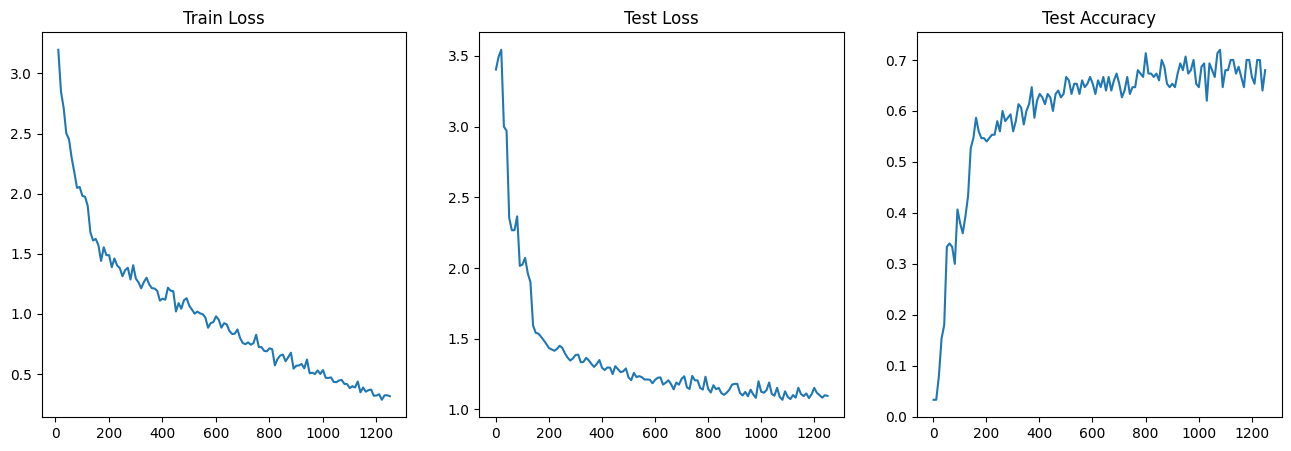


epoch: 19
loss train: 0.31533386558294296
loss test: 1.0958611965179443
lr: 1e-05


ResNet18(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  

In [74]:
cur_iter = 0
iter_list = []
test_accuracy_list = []
test_loss_list = []
train_loss_list = []
for epoch in range(n_epoch):
    loss_train = 0
    train_count = 0
    model.train()
    for X, target in tqdm(dataloader_train, ncols=80):
        cur_iter += 1
        X = X.to(device)
        target = target.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = loss_fn(logits, target)
        loss.backward()
        optimizer.step()

        loss_train += loss.item() * target.size(0)
        train_count += target.size(0)

        if cur_iter % 10 == 1:
            model.eval()
            accuracy, loss_test, _, _ = calc_accuracy(model, dataloader_test)
            iter_list.append(cur_iter)

            test_accuracy_list.append(accuracy)
            test_loss_list.append(loss_test)
            train_loss_list.append(loss_train / train_count)

            show_loss(iter_list, train_loss_list, test_loss_list, test_accuracy_list)

            print('\nepoch:', epoch)
            print('loss train:', loss_train / train_count)
            print('loss test:', loss_test)
            print('lr:', get_lr(optimizer))
            loss_train = 0
            train_count = 0
            model.train()

    scheduler.step()

model.eval()


In [75]:
accuracy, _, y_pred, y_test = calc_accuracy(model, dataloader_test)

assert accuracy.item() >= 0.8, ':('
print('Отлично!')


AssertionError: :(

In [76]:
accuracy

tensor(0.6800)

## <font color='MediumSeaGreen'> **Задание 5 [Bonus][2 балла] (необязательно)** </font>

Выбейте качество не менее **0.85** `Accuracy` любым способом, используя сверточные нейросети.


In [ ]:
pass  # YOUR CODE HERE